# Credit Scoring Model Using Machine Learning

## Objective

The objective of this project is to predict credit risk by classifying applicants into good-credit-risk and bad-credit-risk categories using machine learning algorithms.

## Technologies Used

* Python
* Google Colab
* Pandas and NumPy
* Matplotlib and Seaborn
* Scikit-learn

## Dataset

The project uses the German Credit Risk dataset, containing 1,000 records and 20 input features. The target variable indicates whether an applicant belongs to the good-credit-risk or bad-credit-risk category.

## Methodology

1. Load and explore the dataset.
2. Preprocess numerical and categorical features.
3. Split the data into training and testing sets.
4. Train Logistic Regression, Random Forest, and Gradient Boosting classifiers.
5. Evaluate the models using accuracy, precision, recall, F1-score, and ROC-AUC.
6. Compare model performance and generate predictions.


---



---







In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

columns = [
    "checking_account", "duration", "credit_history",
    "purpose", "credit_amount", "savings_account",
    "employment", "installment_rate", "personal_status",
    "other_debtors", "residence_since", "property",
    "age", "other_installment_plans", "housing",
    "existing_credits", "job", "num_dependents",
    "telephone", "foreign_worker", "credit_risk"
]

df = pd.read_csv(url, sep=r"\s+", header=None, names=columns)

# 0 = good credit; 1 = bad credit
df["credit_risk"] = (df["credit_risk"] == 2).astype(int)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


Missing values: 0

Credit risk distribution:
credit_risk
0    700
1    300
Name: count, dtype: int64


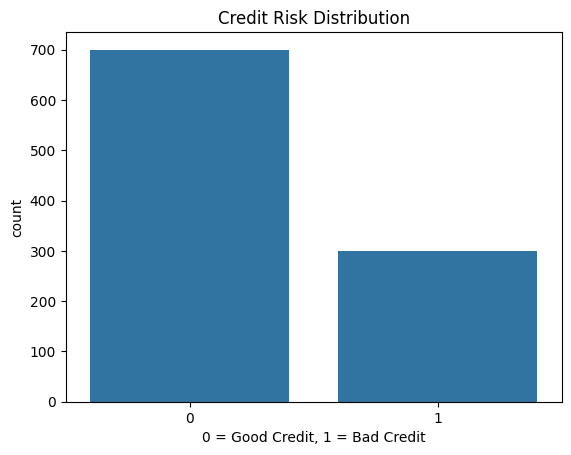

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("\nCredit risk distribution:")
print(df["credit_risk"].value_counts())

sns.countplot(data=df, x="credit_risk")
plt.title("Credit Risk Distribution")
plt.xlabel("0 = Good Credit, 1 = Bad Credit")
plt.show()

In [4]:
X = df.drop("credit_risk", axis=1)
y = df["credit_risk"]

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


In [5]:
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Credit scoring model trained successfully!")

Credit scoring model trained successfully!


In [6]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Good Credit", "Bad Credit"]
))

Accuracy: 0.76
Precision: 0.6765
Recall: 0.3833
F1-score: 0.4894
ROC-AUC: 0.7949

Classification Report:
              precision    recall  f1-score   support

 Good Credit       0.78      0.92      0.84       140
  Bad Credit       0.68      0.38      0.49        60

    accuracy                           0.76       200
   macro avg       0.73      0.65      0.67       200
weighted avg       0.75      0.76      0.74       200



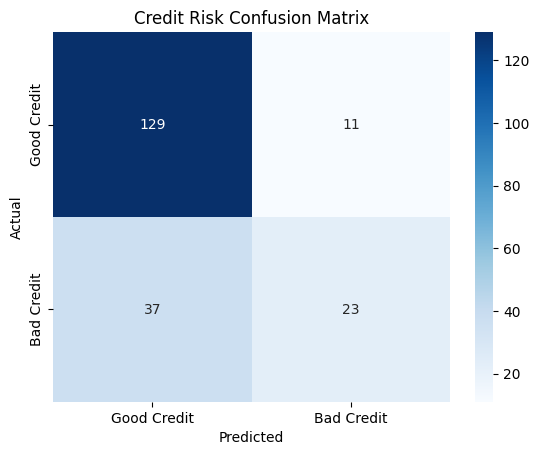

In [7]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Good Credit", "Bad Credit"],
    yticklabels=["Good Credit", "Bad Credit"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Credit Risk Confusion Matrix")
plt.show()

In [8]:
sample = X_test.iloc[[0]]

prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0][1]

print(
    "Prediction:",
    "Bad Credit Risk" if prediction == 1 else "Good Credit Risk"
)
print(f"Estimated bad-risk probability: {probability:.2%}")

display(sample)

Prediction: Good Credit Risk
Estimated bad-risk probability: 33.00%


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker
30,A12,18,A32,A49,1913,A64,A72,3,A94,A101,3,A121,36,A141,A152,1,A173,1,A192,A201


In [9]:
joblib.dump(model, "/content/credit_scoring_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [10]:
from google.colab import files
files.download("/content/credit_scoring_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from sklearn.base import clone

models = {
    "Logistic Regression": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=2000, class_weight="balanced"
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", GradientBoostingClassifier(random_state=42))
    ])
}

results = []

for name, candidate in models.items():
    candidate.fit(X_train, y_train)
    pred = candidate.predict(X_test)
    prob = candidate.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Precision": round(precision_score(y_test, pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, pred, zero_division=0), 4),
        "F1-score": round(f1_score(y_test, pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 4)
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("ROC-AUC", ascending=False))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.75,0.5581,0.8000,0.6575,0.8058
1,Random Forest,0.76,0.6765,0.3833,0.4894,0.7949
2,Gradient Boosting,0.79,0.6800,0.5667,0.6182,0.7919


## Conclusion

The Credit Scoring Model was developed using machine learning techniques to classify applicants into good-credit-risk and bad-credit-risk categories. The German Credit Risk dataset containing 1,000 records was used for training and evaluation.

Three classification algorithms were compared: Logistic Regression, Random Forest, and Gradient Boosting. Gradient Boosting achieved the highest accuracy of 79%, while Logistic Regression achieved the highest recall of 80% and ROC-AUC of 80.58%.

The results demonstrate that different machine learning algorithms have different strengths. Further improvements in feature engineering, model tuning, and evaluation are required before considering real-world applications. This project is intended for educational purposes and should not be used alone to make actual lending decisions.
